# Historical baseline: rentals from the previous week

Predicts hourly rentals at each station using **only past rentals**:

- `last_week` - the same station, same hour, **7 days earlier**
- `avg_4w` - the average of the same hour over the **previous 4 weeks** (a smoother version)

No training is needed. Last week's actuals are always known when the forecast is made (your pipeline forecasts 1 hour ahead).

## 1. Connect to GitHub and load the data

In [6]:
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/amelia-lee-smu/CS610-Applied-Machine-Learning.git"
BRANCH   = "main"     # README links the processed data on branch "feat/eda-for-proposal";
                      # if data/processed is missing on main, change this, delete the cloned folder, re-run
REPO_DIR = Path("CS610-Applied-Machine-Learning")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"])

print("Repo folders:", sorted(p.name for p in REPO_DIR.iterdir() if p.is_dir() and not p.name.startswith(".")))

Repo folders: ['data', 'models', 'notebooks', 'references', 'utilities']


In [7]:
try:
    import pyarrow  # noqa
except ImportError:
    %pip install -q pyarrow

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance

DATA_DIR = REPO_DIR / "data" / "processed"
PRED_DIR = REPO_DIR / "data" / "predictions"

files = sorted(p for p in DATA_DIR.rglob("*") if p.suffix in {".parquet", ".csv"}) if DATA_DIR.exists() else []
if not files:
    raise FileNotFoundError(f"No .parquet/.csv files in {DATA_DIR}. Try another BRANCH in the first cell.")

def read(p):
    return pd.read_parquet(p) if p.suffix == ".parquet" else pd.read_csv(p)

for p in files:   # Git LFS pointer check
    if p.stat().st_size < 300 and b"git-lfs" in p.read_bytes():
        raise RuntimeError(f"{p.name} is a Git LFS pointer - run `git lfs pull` in the repo.")

raw = {p.name: read(p) for p in files}
for name, d in raw.items():
    print(f"{name}: {d.shape}")

test.parquet: (74409, 17)
train_validation.parquet: (520149, 17)


## 2. Identify columns and split (test = 1 Mar - 30 Apr 2021)

In [9]:
OVERRIDE = dict(station=None, target="num_rentals", time=None, date=None, hour=None)   # e.g. dict(target="rental_count")

df_all = pd.concat(raw.values(), ignore_index=True)
cols = {c.lower(): c for c in df_all.columns}

def pick(override, candidates=(), predicate=None):
    if override: return override
    for c in candidates:
        if c in cols: return cols[c]
    if predicate:
        for lc, c in cols.items():
            if predicate(lc): return c
    return None

STATION = pick(OVERRIDE["station"], ["station", "station_name", "start_station_name", "start_station_id", "station_id"],
               lambda c: "station" in c and not any(k in c for k in ("lat", "lng", "lon")))
TARGET  = pick(OVERRIDE["target"], ["rentals", "rental", "rental_count", "rentals_count", "count", "demand", "n_rentals", "trips", "y"])
TIME    = pick(OVERRIDE["time"], ["datetime", "timestamp", "date_time", "time"],
               lambda c: pd.api.types.is_datetime64_any_dtype(df_all[cols[c]]))
DATE    = pick(OVERRIDE["date"], ["date"]) if TIME is None else None
HOUR    = pick(OVERRIDE["hour"], ["hour", "hour_of_day"]) if TIME is None else None

print(dict(STATION=STATION, TARGET=TARGET, TIME=TIME, DATE=DATE, HOUR=HOUR))
missing = [k for k, v in dict(station=STATION, target=TARGET).items() if v is None]
if missing or (TIME is None and (DATE is None or HOUR is None)):
    print("Columns available:", list(df_all.columns))
    raise ValueError(f"Could not detect {missing or 'time columns'} - set OVERRIDE above.")

if TIME is None:
    df_all["_ts"] = pd.to_datetime(df_all[DATE]) + pd.to_timedelta(df_all[HOUR], unit="h")
else:
    df_all["_ts"] = pd.to_datetime(df_all[TIME])

df_all = df_all.drop_duplicates([STATION, "_ts"]).sort_values([STATION, "_ts"]).reset_index(drop=True)
print(f"{df_all[STATION].nunique()} stations, {df_all['_ts'].min()} -> {df_all['_ts'].max()}, {len(df_all):,} rows")

TEST_START = pd.Timestamp("2021-03-01")          # test = 1 Mar - 30 Apr 2021 (as in the README)
test = df_all[df_all["_ts"] >= TEST_START].reset_index(drop=True)
KEYS = [STATION, "_ts"]
print(f"test rows: {len(test):,}")

{'STATION': 'start station name', 'TARGET': 'num_rentals', 'TIME': None, 'DATE': 'date', 'HOUR': 'hour_of_day'}
51 stations, 2020-01-01 00:00:00 -> 2021-04-30 19:00:00, 594,558 rows
test rows: 74,409


## 3. Build the baseline predictions

In [10]:
history = df_all[[STATION, "_ts", TARGET]]

def add_baselines(df, weeks=(1, 2, 3, 4)):
    out = df.copy()
    for w in weeks:
        lag = history.copy()
        lag["_ts"] = lag["_ts"] + pd.Timedelta(weeks=w)      # line history up with the hour being predicted
        out = out.merge(lag.rename(columns={TARGET: f"lag_{w}w"}), on=[STATION, "_ts"], how="left")
    out["last_week"] = out["lag_1w"]
    out["avg_4w"] = out[[f"lag_{w}w" for w in weeks]].mean(axis=1)
    return out

test_b = add_baselines(test)
n0 = len(test_b)
test_b = test_b.dropna(subset=["last_week", "avg_4w"])
print(f"scored rows: {len(test_b):,} of {n0:,}")
test_b[KEYS + [TARGET, "last_week", "avg_4w"]].head()

scored rows: 74,358 of 74,409


,start station name,_ts,num_rentals,last_week,avg_4w
0,5 Corners Library,2021-03-01 00:00:00,0,0.0,0.0
1,5 Corners Library,2021-03-01 01:00:00,0,0.0,0.0
2,5 Corners Library,2021-03-01 02:00:00,0,0.0,0.0
3,5 Corners Library,2021-03-01 03:00:00,0,0.0,0.0
4,5 Corners Library,2021-03-01 04:00:00,0,0.0,0.0


## 4. Evaluate
Poisson deviance needs predictions > 0, so forecasts are clipped at 0.001 ("0 rentals last week" would otherwise give an infinite deviance).

In [11]:
EPS = 1e-3
def metrics(y, p):
    p = np.clip(np.asarray(p, float), EPS, None)
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5,
            "Poisson dev": mean_poisson_deviance(y, p)}

results = pd.DataFrame({c: metrics(test_b[TARGET], test_b[c]) for c in ["last_week", "avg_4w"]}).T
results.round(3)

,MAE,RMSE,Poisson dev
last_week,0.607,1.30,3.677
avg_4w,0.511,1.04,1.799


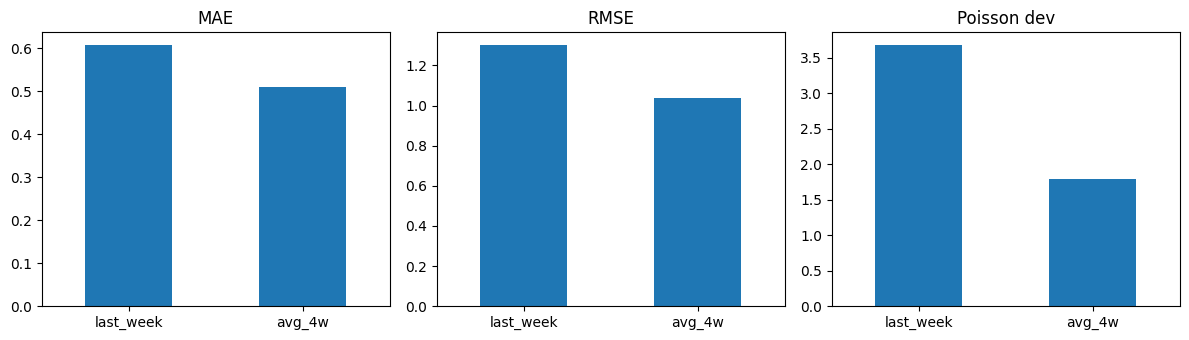

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, m in zip(axes, results.columns):
    results[m].plot.bar(ax=ax, rot=0, title=m)
plt.tight_layout(); plt.show()

## 5. Save predictions
Written to `data/predictions/test_baseline_*.parquet` (same naming as the other models) so the non-zero add-on notebook can pick them up. Commit and push from your own checkout to keep them.

In [13]:
SAVE = True
if SAVE:
    PRED_DIR.mkdir(parents=True, exist_ok=True)
    for c in ["last_week", "avg_4w"]:
        test_b[KEYS + [c]].rename(columns={c: "prediction"}).to_parquet(PRED_DIR / f"test_baseline_{c}.parquet", index=False)
    print("saved:", sorted(p.name for p in PRED_DIR.glob("test_baseline_*")))

saved: ['test_baseline_avg_4w.parquet', 'test_baseline_last_week.parquet']
